In [28]:
data = pd.read_csv("/content/NHANES_HeartDisease_SDoH_Clinical_Final.csv")

print("Shape:", data.shape)
data.head()

Shape: (4671, 21)


,SEQN,heart_disease,RIDAGEYR,sex,race_ethnicity,education,INDFMPIR,food_security,insured,usual_source_care,...,diabetes,smoking,sedentary_minutes,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,BMXBMI,LBDHDD,LBXTC
0,130378.0,0.0,43.0,Male,Non-Hispanic Asian,College graduate or above,5.00,Full food security,Yes,Yes,...,No,Former,360.0,50055.450807,54374.463898,173.0,2.0,27.0,45.0,264.0
1,130379.0,0.0,66.0,Male,Non-Hispanic White,College graduate or above,5.00,Full food security,Yes,Yes,...,No,Former,480.0,29087.450605,34084.721548,173.0,2.0,33.5,60.0,214.0
2,130380.0,0.0,44.0,Female,Other Hispanic,High school/GED,1.41,Full food security,Yes,Yes,...,Yes,Never,240.0,80062.674301,81196.277992,174.0,1.0,29.7,49.0,187.0
3,130386.0,0.0,34.0,Male,Mexican American,Some college/AA degree,1.33,Full food security,Yes,Yes,...,No,Former,180.0,30995.282610,39988.452940,179.0,1.0,30.2,46.0,183.0
4,130387.0,0.0,68.0,Female,Non-Hispanic White,College graduate or above,1.32,Full food security,Yes,Yes,...,No,Never,1200.0,19896.970559,20776.254850,181.0,1.0,42.6,42.0,203.0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

demographic_features = ['RIDAGEYR', 'sex', 'race_ethnicity']
target = 'heart_disease'

demo_df = data[demographic_features + [target]].copy()

In [ ]:
# Check whether previous model objects are available
for name in [
    "rf", "rf_model", "random_forest",
    "best_rf", "X_train", "X_test",
    "y_train", "y_test"
]:
    print(f"{name}: {'Available' if name in globals() else 'Not found'}")

rf: Not found
rf_model: Not found
random_forest: Not found
best_rf: Not found
X_train: Not found
X_test: Not found
y_train: Not found
y_test: Not found


In [29]:
demo_df_encoded = pd.get_dummies(demo_df, columns=['sex', 'race_ethnicity'], drop_first=True)

print("Encoded DataFrame head:")
display(demo_df_encoded.head())

print("\nEncoded DataFrame info:")
demo_df_encoded.info()

Encoded DataFrame head:


,RIDAGEYR,heart_disease,sex_Male,race_ethnicity_Non-Hispanic Asian,race_ethnicity_Non-Hispanic Black,race_ethnicity_Non-Hispanic White,race_ethnicity_Other Hispanic,race_ethnicity_Other Race/Multiracial
0,43.0,0.0,True,True,False,False,False,False
1,66.0,0.0,True,False,False,True,False,False
2,44.0,0.0,False,False,False,False,True,False
3,34.0,0.0,True,False,False,False,False,False
4,68.0,0.0,False,False,False,True,False,False



Encoded DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4671 entries, 0 to 4670
Data columns (total 8 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   RIDAGEYR                               4671 non-null   float64
 1   heart_disease                          4671 non-null   float64
 2   sex_Male                               4671 non-null   bool   
 3   race_ethnicity_Non-Hispanic Asian      4671 non-null   bool   
 4   race_ethnicity_Non-Hispanic Black      4671 non-null   bool   
 5   race_ethnicity_Non-Hispanic White      4671 non-null   bool   
 6   race_ethnicity_Other Hispanic          4671 non-null   bool   
 7   race_ethnicity_Other Race/Multiracial  4671 non-null   bool   
dtypes: bool(6), float64(2)
memory usage: 100.5 KB


In [30]:
X = demo_df_encoded.drop(target, axis=1)
y = demo_df_encoded[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Training set size: {len(X_train)} samples")
print(f"Test set size: {len(X_test)} samples")
print(f"Target distribution in training set:\n{y_train.value_counts(normalize=True)}")
print(f"Target distribution in test set:\n{y_test.value_counts(normalize=True)}")

Training set size: 3269 samples
Test set size: 1402 samples
Target distribution in training set:
heart_disease
0.0    0.908229
1.0    0.091771
Name: proportion, dtype: float64
Target distribution in test set:
heart_disease
0.0    0.907989
1.0    0.092011
Name: proportion, dtype: float64


In [31]:
model = LogisticRegression(random_state=42, solver='liblinear')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nModel Coefficients:")
coefficients = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_[0]})
display(coefficients.sort_values(by='Coefficient', ascending=False))

Classification Report:
              precision    recall  f1-score   support

         0.0       0.91      1.00      0.95      1273
         1.0       0.00      0.00      0.00       129

    accuracy                           0.91      1402
   macro avg       0.45      0.50      0.48      1402
weighted avg       0.82      0.91      0.86      1402


Confusion Matrix:
[[1273    0]
 [ 129    0]]

Model Coefficients:


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Feature,Coefficient
1,sex_Male,0.445081
0,RIDAGEYR,0.060794
5,race_ethnicity_Other Hispanic,-0.121395
2,race_ethnicity_Non-Hispanic Asian,-0.126391
6,race_ethnicity_Other Race/Multiracial,-0.208479
3,race_ethnicity_Non-Hispanic Black,-0.261603
4,race_ethnicity_Non-Hispanic White,-0.295938


In [32]:
# Check whether previous model objects are available
for name in [
    "rf", "rf_model", "random_forest",
    "best_rf", "X_train", "X_test",
    "y_train", "y_test"
]:
    print(f"{name}: {'Available' if name in globals() else 'Not found'}")

rf: Not found
rf_model: Available
random_forest: Not found
best_rf: Not found
X_train: Available
X_test: Available
y_train: Available
y_test: Available


In [33]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining variable types:")
print(X_train.dtypes)

print("\nMissing values in training data:")
print(X_train.isnull().sum().sum())

print("\nFirst five rows:")
display(X_train.head())

X_train shape: (3269, 7)
X_test shape: (1402, 7)

Training variable types:
RIDAGEYR                                 float64
sex_Male                                    bool
race_ethnicity_Non-Hispanic Asian           bool
race_ethnicity_Non-Hispanic Black           bool
race_ethnicity_Non-Hispanic White           bool
race_ethnicity_Other Hispanic               bool
race_ethnicity_Other Race/Multiracial       bool
dtype: object

Missing values in training data:
0

First five rows:


,RIDAGEYR,sex_Male,race_ethnicity_Non-Hispanic Asian,race_ethnicity_Non-Hispanic Black,race_ethnicity_Non-Hispanic White,race_ethnicity_Other Hispanic,race_ethnicity_Other Race/Multiracial
543,65.0,False,False,False,True,False,False
302,62.0,False,False,False,False,True,False
2316,52.0,False,True,False,False,False,False
2964,74.0,False,False,False,True,False,False
947,64.0,True,False,True,False,False,False


In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_prob = rf_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print("Random Forest trained successfully!")
print(f"Test ROC-AUC: {auc:.3f}")

Random Forest trained successfully!
Test ROC-AUC: 0.695


The analysis revealed that the model has moderate ability to distinguish participants with heart disease from those without it, using only age, sex, and race/ethnicity. The AUC is .695. The next step is to caculate the build in features.

Built-in Feature Importance:


,Feature,Built_in_Importance
0,RIDAGEYR,0.895826
1,sex_Male,0.046554
4,race_ethnicity_Non-Hispanic White,0.014904
3,race_ethnicity_Non-Hispanic Black,0.012979
6,race_ethnicity_Other Race/Multiracial,0.010874
5,race_ethnicity_Other Hispanic,0.010102
2,race_ethnicity_Non-Hispanic Asian,0.008762


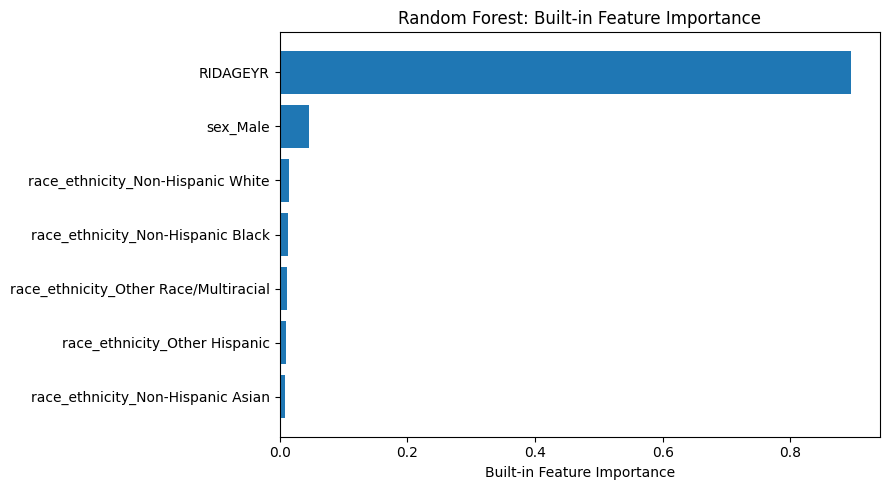

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate built-in feature importance
built_in = pd.DataFrame({
    "Feature": X_train.columns,
    "Built_in_Importance": rf_model.feature_importances_
})

# Sort from most important to least important
built_in = built_in.sort_values(
    "Built_in_Importance", ascending=False
)

print("Built-in Feature Importance:")
display(built_in)

# Plot results
plt.figure(figsize=(9, 5))
plt.barh(
    built_in["Feature"],
    built_in["Built_in_Importance"]
)
plt.xlabel("Built-in Feature Importance")
plt.title("Random Forest: Built-in Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Age accounts for approximately 89.6% of the total built-in importance in the Random Forest model. However, there is a methdological consideration that must be considered. Random Forest's standard built-in importance can favor continous variables like age because more potential splitting points are offered in comparison to binary variables.

In [36]:
#Calculating permutation importance

from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate permutation importance on held-out test data
perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

# Create results table
perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Permutation_Importance": perm.importances_mean,
    "Standard_Deviation": perm.importances_std
})

# Sort by permutation importance
perm_df = perm_df.sort_values(
    "Permutation_Importance",
    ascending=False
)

print("Permutation Feature Importance:")
display(perm_df)

Permutation Feature Importance:


,Feature,Permutation_Importance,Standard_Deviation
0,RIDAGEYR,0.158428,0.025673
1,sex_Male,0.009039,0.012201
5,race_ethnicity_Other Hispanic,0.008075,0.003191
4,race_ethnicity_Non-Hispanic White,0.007152,0.009678
2,race_ethnicity_Non-Hispanic Asian,0.004355,0.003563
3,race_ethnicity_Non-Hispanic Black,-0.000665,0.003516
6,race_ethnicity_Other Race/Multiracial,-0.005948,0.002508


Although the Random Forest used the other/multiracial variable when constructing trees, shufflint it in the data slightly improved AUC on average than reducing it.

Overall findings: For this exercise, I used a Random Forest classifier to predict heart disease using demographic characteristics (age, sex, and race/ethnicity) from the NHANES dataset (N = 4,671). The model achieved a test AUC of .695. I then compared built-in feature importance with permutation importantion calculated on the held-out test dataset. Both methods identified as as the most important predictor. However, they differed in how they ranked several race/ethnicity indicators.

One disagreement involved the Other Race/Multiracial indicator, which ranked fifth in the built-in importance (0.0109) but last in permutation importance (-0.0059). Although the Random Forest used this variable to make splits during training, randomly shuffling it in the test data slightly imporoved model performance on average.

The difference shows us that a varible's contribution to constructing decsion trees does not necessarily translate into improved predictive performance on new data. It also highlights the importance of considering multiple apporaches to interpreting machine learning models, especially when examining demographic characteristics.

## Part 2: SHAP Analysis and Random Noise Experiment

In [37]:
import numpy as np

# Create copies of the original training and test data
X_train_noise = X_train.copy()
X_test_noise = X_test.copy()

# Generate random noise
rng = np.random.default_rng(42)

X_train_noise["random_noise"] = rng.normal(
    size=len(X_train_noise)
)

X_test_noise["random_noise"] = rng.normal(
    size=len(X_test_noise)
)

# Check the new variables
print("Original predictors:", X_train.shape[1])
print("Predictors with noise:", X_train_noise.shape[1])

X_train_noise.head()

Original predictors: 7
Predictors with noise: 8


,RIDAGEYR,sex_Male,race_ethnicity_Non-Hispanic Asian,race_ethnicity_Non-Hispanic Black,race_ethnicity_Non-Hispanic White,race_ethnicity_Other Hispanic,race_ethnicity_Other Race/Multiracial,random_noise
543,65.0,False,False,False,True,False,False,0.304717
302,62.0,False,False,False,False,True,False,-1.039984
2316,52.0,False,True,False,False,False,False,0.750451
2964,74.0,False,False,False,True,False,False,0.940565
947,64.0,True,False,True,False,False,False,-1.951035


The above output demonstrates to us the thre are 7 original predictors, 8 predictors with noise, and the new random noise column contains randomly generated numerical values. The next step in the process is to retrain the the random forest model with the noise.

In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd

# Train a new Random Forest with random noise
rf_noise = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_noise.fit(X_train_noise, y_train)

# Evaluate model performance
y_prob_noise = rf_noise.predict_proba(X_test_noise)[:, 1]

auc_noise = roc_auc_score(y_test, y_prob_noise)

print("Original model AUC: 0.695")
print("Model with noise AUC:", round(auc_noise, 3))

# Calculate built-in feature importance
noise_importance = pd.DataFrame({
    "Feature": X_train_noise.columns,
    "Importance": rf_noise.feature_importances_
}).sort_values("Importance", ascending=False)

display(noise_importance)

Original model AUC: 0.695
Model with noise AUC: 0.631


,Feature,Importance
7,random_noise,0.472751
0,RIDAGEYR,0.458882
1,sex_Male,0.026977
4,race_ethnicity_Non-Hispanic White,0.011790
3,race_ethnicity_Non-Hispanic Black,0.008735
5,race_ethnicity_Other Hispanic,0.007545
6,race_ethnicity_Other Race/Multiracial,0.006812
2,race_ethnicity_Non-Hispanic Asian,0.006509


Before the random noise, age represented approximately 89.6% of the model's built in performance. After adding the noise, it now accounts for approximately 47.3% and age accounts for approximaely 45.9%. However, it does reduce the AUC accuracy to .631 in comparison to .695. This suggests tha the noise model showed worse discrimination between patients with and without heart disease. The next step is the permutation importance.

In [39]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Permutation importance for model with noise
perm_noise = permutation_importance(
    rf_noise,
    X_test_noise,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

# Create results table
perm_noise_df = pd.DataFrame({
    "Feature": X_test_noise.columns,
    "Permutation_Importance": perm_noise.importances_mean,
    "Standard_Deviation": perm_noise.importances_std
}).sort_values(
    "Permutation_Importance",
    ascending=False
)

display(perm_noise_df)

,Feature,Permutation_Importance,Standard_Deviation
0,RIDAGEYR,0.113823,0.020096
1,sex_Male,0.013943,0.016488
5,race_ethnicity_Other Hispanic,0.008114,0.005017
2,race_ethnicity_Non-Hispanic Asian,-0.003474,0.003413
3,race_ethnicity_Non-Hispanic Black,-0.004265,0.005681
6,race_ethnicity_Other Race/Multiracial,-0.009640,0.005112
4,race_ethnicity_Non-Hispanic White,-0.020795,0.011766
7,random_noise,-0.051637,0.018270


After adding a random variable to the NHANES heart disease prediction model, I saw a difference between the Random Forest importance and permutation importance. The random noise ranked first at .4728 slightly above age .4589. However, the permutation importance ranked random noise last (-0.0516), while age ramined the strongest predictive .1138.

The negative permutation importance suggests that randomly shuffling the noise variable improved the model's test AUC on average. This suggests that the Rondom Forest may have learned patterns from random noise that did not work well to the the unseen data.

These findings suggest that high bulit-in feature importance does not mean or suggest predictive value. This also highlights the importance of comparing different interpretation methods.

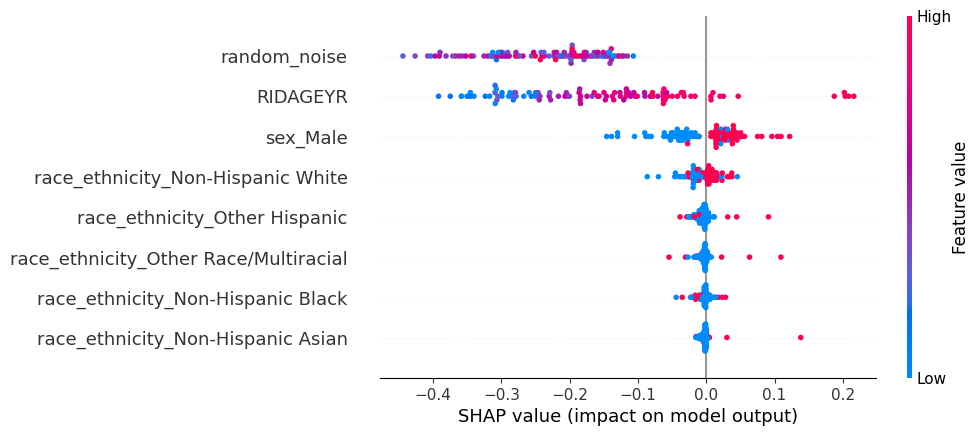

In [40]:
!pip -q install shap

import shap
import matplotlib.pyplot as plt

# Use 100 observations from the test dataset
X_sample = X_test_noise.sample(
    n=100,
    random_state=42
)

# Calculate SHAP values
explainer = shap.TreeExplainer(rf_noise)
shap_values = explainer(X_sample)

# Plot SHAP values for heart disease (class 1)
shap.plots.beeswarm(
    shap_values[:, :, 1],
    max_display=8
)

The above findings reveal that random noise ranked first, follwed by age, and sex. Although random noise had no meaningful relationship with heart disease, the Random Forest assinged it substantial influence in generating predictions. This finding was consistent with the built-in feature importance results, which also ranked random noise first .4728.

However, permutation importance ranked random noise last (-.0516) suggesting that shuffling the varible improved test-set AUC on average. This discrepancy suggest that the model learned patterns involving random noise that did not generalize well to the unseen data.

Age was the more interpretable SHAP pattern, with older ages contributing to higher predicted probabilities of heart disease. Overall, these findings highlight the importance of distinguishing between features that influence model predictions and features that improve performance.

Rudin (2019)

Basically, what I took from the three pages of the article is that there is an important distinction between explaining the black box model after it has been developed and creating a model that is inherently interpretable from the beginning. One of the central arguments is that more complex models are not necessarily more accurate umm especially when we work with structure data.

I found this fascinating and relevant to the NHANES heart disease analysis. So, when I introduced random noise into the random forest model, the noise ranked 1st in built-in importance and SHAP, but last in permutation importance. This raised questions for me about how much confidence we should place in feature importance results without examining whether those features improve predictive performance.

I agree with Rudin that interpretability is important in healthcare, where predictions could potentially influence decisions about patients. Overall, my takeaway is that we need to evaluate not only how well a model predicts an outcome, but also whether we can understand and trust the information it uses to make those predictions.
